# TP3 — Algoritmo de detección de ofertas hoteleras

**Grupo 2** · Jeremías Taran, Martín Gabriel Gómez, Jael Mataloni, Francisco Cisneros
**Diplomatura en Ciencia de Datos · Mentoría ID90Travel 2026**

**Pregunta:** dado el precio de una búsqueda hotelera y la historia de su mercado, ¿es una oferta?

## Respuesta corta

| Lo que pide el TP3 | Respuesta | Sección |
|---|---|---|
| Algoritmo | Regla híbrida: $z_{\log} < -1$ **y** al menos 20% de descuento sobre la mediana del contexto, con una cascada de fallback cuando el contexto tiene pocos datos | 2 |
| Evaluación sin etiquetas | Los baselines se calculan con 2024 y se evalúa sobre 2025, contra la regla aplicada al mercado real de 2025. Se suman precios sintéticos con verdad conocida | 3 y 4 |
| Resultado | F1 0,76, precision 0,73, FPR 5,4%, decide en el 99,8% de las búsquedas. Le gana a todas las reglas simples y empata con un modelo de boosting | 4 y 5 |
| Sensibilidad al mercado del TP2 | Usar solo el destino cae a F1 0,64. Sin fallback se decide en menos de la mitad de los casos. La semana del mes sobre-segmenta | 6 |
| Limitaciones | Deriva de precios entre años, mercado sin categoría de hotel y la unidad de `avg_price_average` | 7 y 9 |

## Cómo está organizado

Este notebook **no recalcula nada**: lee las tablas que deja el pipeline en `outputs/full/` asi puede correrse rapido.

- El cálculo completo está en `src/hotel_deals/` y se corre con `python scripts/run_pipeline.py --source full` (~30 min).
- El anexo `anexo_tp3_pipeline_completo.ipynb` corre ese pipeline y muestra todas las tablas de detalle.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from hotel_deals import config, figures  # noqa: E402
from hotel_deals.service import DealDetector  # noqa: E402

# Resultados del dataset completo si están; si no, los de la muestra de 300k.
SOURCE = "full" if (config.output_dir("full") / "resumen.json").exists() else "sample"
OUT = config.output_dir(SOURCE)
T = figures.load(SOURCE)
S = json.loads((OUT / "resumen.json").read_text(encoding="utf-8"))
pd.set_option("display.width", 160)


def tabla(df, pct_cols=(), dec_cols=()):
    """Formatea una tabla para leerla rápido: porcentajes con 1 decimal, métricas con 3."""
    df = df.copy()
    for c in pct_cols:
        df[c] = df[c].map(lambda v: "—" if pd.isna(v) else f"{v:.1%}")
    for c in dec_cols:
        df[c] = df[c].map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
    return df


def ver(fig):
    """Muestra un gráfico de hotel_deals.figures y lo cierra."""
    display(fig)
    plt.close(fig)


def nombre(algoritmo):
    return figures.NOMBRES.get(algoritmo, algoritmo)


print(f"Fuente de los resultados: {SOURCE}  ({OUT})")

Fuente de los resultados: full  (C:\Users\mgg15\OneDrive\Documents\Martin\UNC\CUARTO AÑO\Diplo Datos\Mentoria\TP2_entrega_francisco\TP3_entrega\outputs\full)


---
## 1. Datos y precio comparable

Se parte de la curación del TP2. Para que precios de búsquedas distintas se puedan comparar, se lleva todo a **USD por habitación-noche-persona**:

$$\text{price\_std} = \frac{\text{avg\_price\_average}}{\text{noches} \times \text{habitaciones} \times \text{personas}}$$

Se agregan dos reglas:

- **Piso de 1 USD** por habitación-noche-persona. Por debajo son errores de carga, y el detector los marcaría como ofertas.
- **Corte superior en el percentil 99,9**, calculado solo con 2024 para no filtrar información del test.

In [2]:
embudo = pd.read_csv(OUT / "embudo_curacion.csv")
embudo["% retenido"] = embudo["filas"] / embudo["filas"].iloc[0]
display(tabla(embudo, pct_cols=["% retenido"]))
print(f"Train (check-in 2024): {S['n_train']:,} búsquedas")
print(f"Test  (check-in 2025): {S['n_test']:,} búsquedas")
print(f"Ofertas: {S['train_prevalence']:.1%} en 2024 y {S['test_prevalence']:.1%} en 2025")

,etapa,filas,% retenido
0,Datos crudos,5158190,100.0%
1,Denominadores válidos y noches <= 30,5158163,100.0%
2,"Precio total en (0, 50.000] USD",5157438,100.0%
3,price_std >= 1 USD (piso de error),5145974,99.8%


Train (check-in 2024): 2,512,170 búsquedas
Test  (check-in 2025): 2,633,804 búsquedas
Ofertas: 15.1% en 2024 y 15.0% en 2025


---
## 2. El algoritmo

### 2.1 La regla

Para cada búsqueda se busca su **contexto** (el mercado definido en el TP2: `destino × mes × semana del mes × duración de estadía`) y se compara el precio contra la historia de ese contexto:

$$\text{es oferta} \iff { \frac{\ln(\text{price\_std}) - \mu_{\log}}{\sigma_{\log}} < -1} \quad\text{y}\quad \underbrace{1 - \frac{\text{price\_std}}{\text{mediana}} \ge 0{,}20}_{\text{ahorro real}}$$

**Por qué en logaritmo** Los precios de hotel no tienen valores negativos y tienen cola larga. En escala lineal esa cola infla el desvío y un precio barato de verdad no llega a $z < -1$. En logaritmo la distancia se mide en proporciones, que es como se percibe un descuento.

**Por qué además el 20%.** En mercados muy planos (todos los hoteles entre 40 y 41 USD) un precio puede tener $z$ muy negativo y ahorrar centavos. El descuento mínimo evita llamar oferta a eso.



En código es esto (la implementación vectorizada está en `src/hotel_deals/detectors.py`):

In [3]:
import math


def es_oferta(price_std, mediana, mu_log, sigma_log, z_umbral=-1.0, descuento_min=0.20):
    z_log = (math.log(price_std) - mu_log) / sigma_log
    descuento = 1 - price_std / mediana
    return (z_log < z_umbral) and (descuento >= descuento_min)

### 2.2 Ejemplo 

Orlando, check-in el 10/07/2025, 3 noches, 2 adultos, 1 habitación. Se prueban tres precios totales :

In [4]:
detector = DealDetector()
busqueda = {"city": "Orlando", "state": "Florida", "country": "United States", "country_code": "US",
            "date_start": "2025-07-10", "nights": 3, "adults": 2, "kids": 0, "rooms": 1}
ejemplo = detector.evaluate_frame(pd.DataFrame([{**busqueda, "price_total": p} for p in [30, 40, 150]]))
ejemplo.insert(0, "precio_total", [30, 40, 150])
display(ejemplo[["precio_total", "price_std", "baseline_median", "discount", "z_log", "decision"]])
for p, e in zip(ejemplo["precio_total"], ejemplo["explanation"]):
    print(f"{p:>4} USD → {e}")

,precio_total,price_std,baseline_median,discount,z_log,decision
0,30,5.0000,14.7989,0.6621,-1.3488,deal
1,40,6.6667,14.7989,0.5495,-0.9901,no_deal
2,150,25.0000,14.7989,-0.6893,0.6578,no_deal


  30 USD → Oferta: 5.00 USD por habitación-noche-persona está 66% debajo de la mediana de destino × mes × semana × estadía (14.80 USD, 171 búsquedas) y su z_log es -1.35 (umbral -1).
  40 USD → No es oferta: 6.67 USD por habitación-noche-persona está 55% debajo de la mediana de destino × mes × semana × estadía (14.80 USD, 171 búsquedas), pero su z_log es -0.99 y no llega al umbral -1.
 150 USD → No es oferta: 25.00 USD por habitación-noche-persona está 69% encima de la mediana de destino × mes × semana × estadía (14.80 USD, 171 búsquedas).


El precio de 40 USD muestra por qué hacen falta las dos condiciones: tiene 55% de descuento, pero en ese mercado la dispersión es tan grande que ese precio todavía es normal ($z_{\log} = -0{,}99$).


### 2.3 Cascada de fallbacks

Solo una parte de los contextos tiene historia suficiente. Se exigen **30 búsquedas independientes** (filas distintas, sin contar repeticiones). Si el contexto no llega, se baja a uno más amplio:

| Nivel | Contexto |
|---|---|
| L1 | destino × mes × semana × estadía (el del TP2) |
| L2 | destino × mes × estadía |
| L3 | destino × mes |
| L4 | destino × estadía |
| L5 | destino |
| L6 | país × mes × estadía |
| L7 | nada alcanza: la respuesta es `insufficient_data`, no se inventa |

Cada respuesta informa qué nivel usó, así se sabe cuánta confianza tiene.

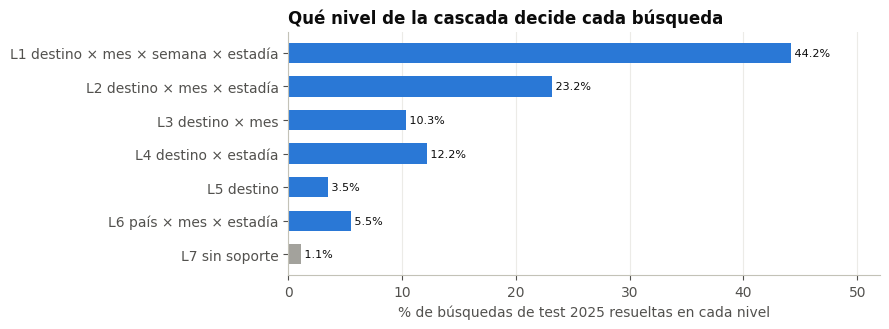

In [5]:
ver(figures.cobertura_cascada(T))

El 44% de las búsquedas de 2025 se decide con el contexto completo del TP2 y el 99% con algún nivel. Solo el 1,1% queda sin respuesta.

---
## 3. Cómo evaluamos sin etiquetas externas

No existe un dato que diga "esto fue una oferta". Se combinan tres evaluaciones:

| Evaluación | Cómo se arma | Qué responde |
|---|---|---|
| **Split temporal** | Baselines, corte de outliers y modelos se ajustan **solo con 2024**. Se evalúa sobre 2025 | ¿La historia permite anticipar qué precios van a ser oferta? |
| **Casos sintéticos** | Precios fijados en 0,3 a 1,5 veces la mediana del mercado | ¿Responde bien a descuentos conocidos? |
| **Test set compartido** | 3.600 búsquedas reales, 2.400 sintéticas y 11 casos borde, evaluados a través de la API | ¿Funciona de punta a punta, incluidos los casos raros? |

**La etiqueta del split temporal.** Es la misma regla, pero calculada sobre la **distribución real del mercado 2025**, que ningún detector ve. El detector solo conoce 2024.

**Lo que esto no resuelve.** La etiqueta sigue siendo una definición operativa. Por eso se agregan los casos sintéticos y se compara contra modelos de ML que no conocen la regla.

**Métricas.** La prioridad es la **precision** y la **tasa de falsos positivos (FPR)**: mostrar como oferta algo que no lo es le hace perder confianza al usuario. Se elige por **F1** y se exige **cobertura** (un detector perfecto que decide sobre el 2% de los casos no sirve). Accuracy no sirve para elegir: con 15% de ofertas, decir siempre "no" ya da 85%.

---
## 4. Resultados sobre 2025

| | Algoritmo | Idea |
|---|---|---|
| A | Naive aleatorio | Marca al azar con la proporción de ofertas de 2024 |
| B | Mediana −20% | Precio al menos 20% bajo la mediana del contexto |
| C | Z-score gaussiano | $z < -1$ en escala lineal (propuesta del docente) |
| D | Percentil 10 | Precio debajo del p10 del contexto |
| **E** | **Híbrido + cascada** | **La regla de la sección 2 (elegido)** |
| F | HistGradientBoosting | ML con features de la búsqueda: destino, fechas, noches, personas, precio |
| G | Random Forest | Igual que F |

Los modelos F y G **no** reciben `price_bucket`, la mediana, el $z$ ni percentiles: tienen que aprender solos qué precio es bajo en cada mercado.

,precision,recall,f1,fpr,cobertura
algoritmo,,,,,
A Naive aleatorio,0.151,0.151,0.151,15.0%,100.0%
B Mediana −20%,0.375,0.965,0.540,28.5%,99.8%
C Z-score gaussiano,0.783,0.461,0.580,2.3%,99.8%
D Percentil 10,0.760,0.718,0.738,4.0%,99.8%
E Híbrido + cascada,0.725,0.806,0.764,5.4%,99.8%
F HistGradientBoosting,0.756,0.785,0.770,4.5%,100.0%
G Random Forest,0.713,0.743,0.728,5.3%,100.0%


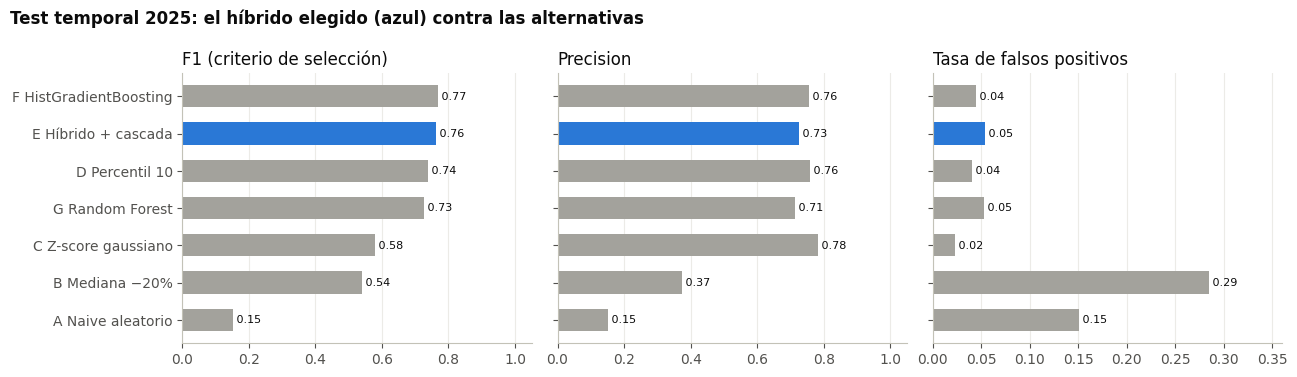

In [6]:
m = T["metricas"].copy()
m = m[m["algoritmo"] != "E2_hibrido_sin_semana_posthoc"]
m["algoritmo"] = m["algoritmo"].map(nombre)
display(tabla(m[["algoritmo", "precision", "recall", "f1", "fpr", "cobertura"]],
              pct_cols=["fpr", "cobertura"], dec_cols=["precision", "recall", "f1"]).set_index("algoritmo"))
ver(figures.comparacion_algoritmos(T))

**Analisis:**

- **E y F están prácticamente empatados** (F1 0,764 contra 0,770). Las reglas simples quedan bastante abajo.
- **C (z gaussiano) es muy preciso pero detecta menos de la mitad** de las ofertas: es lo que predice el argumento del logaritmo.
- **B tiene recall alto, pero 29% de falsos positivos**: marca como oferta casi 4 de cada 10 búsquedas.

**Por qué E y no F**, si F tiene un F1 apenas mayor:

1. **Explicable:** cada respuesta dice contra qué mediana se comparó, cuánto descuento hay y en qué nivel de la cascada (sección 2.2).
2. **Pocos datos de entrada:** solo usa los campos de la búsqueda. F necesita `avg_hotel_count`, que no viene en la query.
3. **Fácil de mantener:** se actualiza recalculando medianas, sin reentrenar ni recalibrar umbrales.


### 4.1 Control: ¿qué pasa si se evalúa dentro del mismo año?

In [7]:
ctrl = pd.DataFrame({
    "F1 split aleatorio 2024": T["aleatorio"].set_index("algoritmo")["f1"],
    "F1 split temporal 2025": T["metricas"].set_index("algoritmo")["f1"],
}).dropna()
ctrl.index = ctrl.index.map(nombre)
display(ctrl.round(3))

,F1 split aleatorio 2024,F1 split temporal 2025
algoritmo,,
A Naive aleatorio,0.150,0.151
B Mediana −20%,0.567,0.540
C Z-score gaussiano,0.636,0.580
D Percentil 10,0.832,0.738
E Híbrido + cascada,0.919,0.764
F HistGradientBoosting,0.808,0.770


Con un 80/20 aleatorio dentro de 2024, el mismo detector da F1 0,92. Al pasar a 2025 cae a 0,76. La diferencia es el efecto de que **los precios cambian de un año a otro**. Evaluar dentro del mismo período habría dado una imagen demasiado optimista.

---
## 5. Casos controlados: precios sintéticos

Se toman búsquedas reales de 2025 y se reemplaza el precio por *factor × mediana del mercado*. Como el precio se fija a mano, se sabe de antemano qué debería pasar. La línea gris punteada es la definición de oferta aplicada a esos precios.

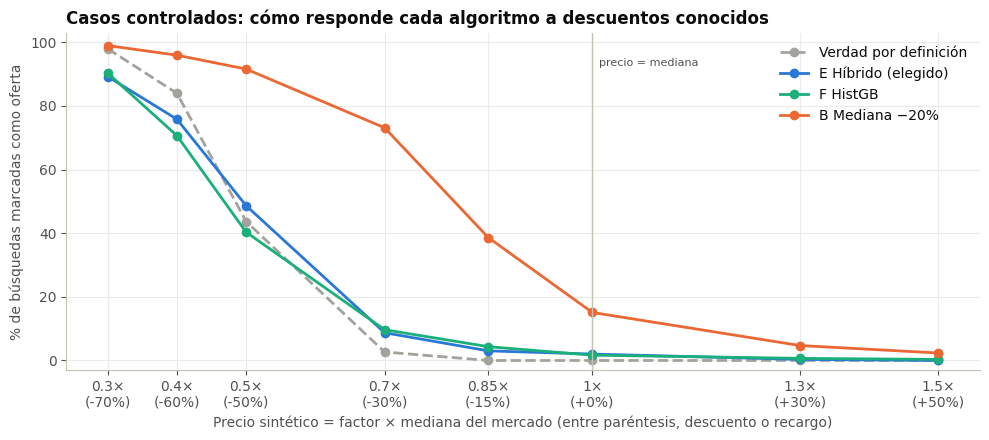

In [8]:
ver(figures.respuesta_descuentos(T))

**Analisis:**

- **E y F siguen la curva de la definición:** marcan casi todo con −70%, muy poco con −30% y casi nada con precios iguales o mayores a la mediana.
- **B marca el 15% de los precios iguales a la mediana**: la mediana de 2024 quedó vieja porque el mercado se movió.
- **Un −30% no es oferta en este mercado.** Los mercados mezclan hoteles económicos y de lujo, así que la dispersión es grande. Un precio 30% más bajo suele ser un hotel más barato y no una anomalía. La definición recién marca de forma consistente con −60% o más.

---
## 6. Sensibilidad a la definición de mercado 

Se deja fija la etiqueta y se cambia solo cómo el detector arma el contexto.

,precision,recall,f1,fpr,cobertura
variante,,,,,
solo L1 (sin fallback),0.764,0.866,0.812,4.0%,44.6%
cascada sin semana (L2..L6),0.745,0.806,0.775,4.9%,99.8%
cascada sin nivel país (L1..L5),0.721,0.806,0.761,5.5%,94.3%
solo destino (L5),0.641,0.646,0.644,6.4%,94.3%
cascada completa (L1..L6),0.725,0.806,0.764,5.4%,99.8%


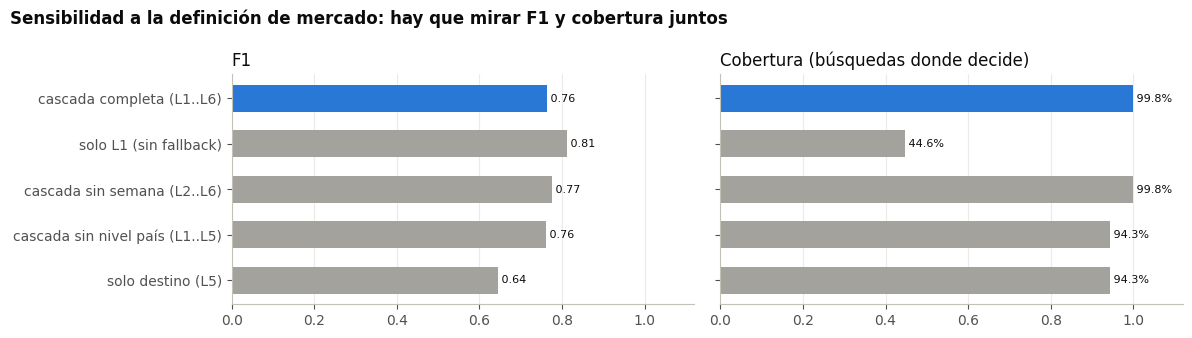

In [9]:
sens = T["sensibilidad"]
ctx = sens[sens["bloque"] == "definición de contexto"]
display(tabla(ctx[["variante", "precision", "recall", "f1", "fpr", "cobertura"]],
              pct_cols=["fpr", "cobertura"], dec_cols=["precision", "recall", "f1"]).set_index("variante"))
ver(figures.sensibilidad_contexto(T))

**Cómo se lee:**

- **Solo el contexto del TP2, sin fallback:** es el más preciso (F1 0,81), pero decide en menos de la mitad de las búsquedas. Por eso hace falta la cascada.
- **Solo destino:** F1 0,64. El mes y la duración de la estadía sí importan; sacarlos mezcla temporada alta con baja.
- **Sin semana del mes:** mejora un poco (F1 0,775). Con un solo año de historia, la celda por semana es demasiado chica. Como esto se vio mirando el test, se recomienda confirmarlo con datos nuevos antes de cambiarlo.
- **Nivel país:** suma unos 5 puntos de cobertura sin perder calidad.

### 6.1 Otros parámetros

precision     f1   fpr cobertura
bloque                             variante                                             
soporte_minimo (n_records)         >= 10                    0.683  0.726  6.4%    100.0%
                                   >= 30                    0.725  0.764  5.4%     99.8%
                                   >= 50                    0.720  0.757  5.5%     99.6%
                                   >= 100                   0.694  0.732  6.0%     98.9%
unidad de soporte                  demand_weight >= 30      0.691  0.736  6.2%    100.0%
umbral descuento (z_log < -1)      >= 10%                   0.725  0.764  5.4%     99.8%
                                   >= 20%                   0.725  0.764  5.4%     99.8%
                                   >= 30%                   0.727  0.764  5.4%     99.8%
winsorización (recalcula etiqueta) p99 (cap 332 USD)        0.728  0.764  5.4%     99.8%
                                   p99.5 (cap 489 USD)      0.727  0.764  5.4%     99.8%
                                   p99.9 (cap 1107 USD)     0.725  0.764  5.4%     99.8%
                                   sin winsorizar           0.724  0.763  5.4%     99.8%

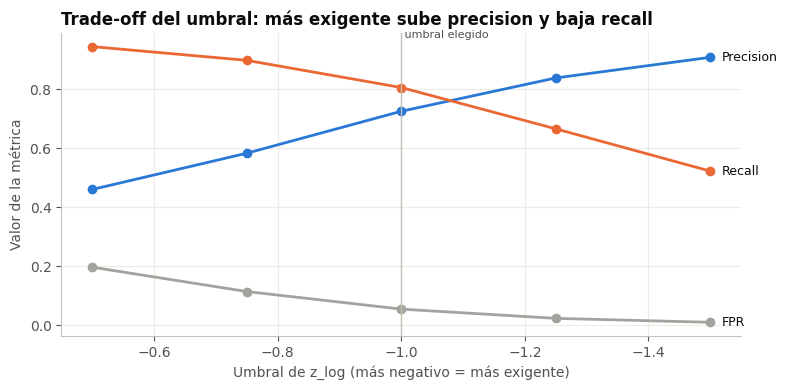

In [10]:
otros = sens[sens["bloque"].isin(["soporte_minimo (n_records)", "unidad de soporte", "umbral descuento (z_log < -1)",
                                  "winsorización (recalcula etiqueta)"])]
display(tabla(otros[["bloque", "variante", "precision", "f1", "fpr", "cobertura"]],
              pct_cols=["fpr", "cobertura"], dec_cols=["precision", "f1"]).set_index(["bloque", "variante"]))
ver(figures.umbral_zlog(T))

- **Soporte mínimo:** 30 búsquedas es el mejor punto. Con 10 los baselines son ruidosos; con 100 se pierde cobertura.
- **Contar búsquedas, no demanda:** usar `count_repeated` como soporte empeora la precision, porque las repeticiones no aportan información nueva.
- **Umbral de $z_{\log}$:** es la perilla del negocio. Con $-1{,}25$ el FPR baja al 2,3% a cambio de recall (modo conservador).
- **Descuento mínimo y corte de outliers:** casi no cambian nada. Con la dispersión observada, $z_{\log} < -1$ ya implica más de 20% de descuento.

---
## 7.

In [11]:
perfil = pd.read_csv(OUT / "perfil_errores_hibrido.csv").set_index("error_tipo")
perfil = perfil.rename(index={"FP": "Falsos positivos", "FN": "Falsos negativos", "ok": "Aciertos"})
display(tabla(perfil[["n", "descuento_mediano", "z_log_mediano", "cambio_mediana_mercado"]].reset_index(),
              pct_cols=["descuento_mediano", "cambio_mediana_mercado"], dec_cols=["z_log_mediano"]))

,error_tipo,n,descuento_mediano,z_log_mediano,cambio_mediana_mercado
0,Falsos negativos,75970,41.2%,-0.733,25.1%
1,Falsos positivos,119546,54.2%,-1.201,-20.4%
2,Aciertos,2409425,-0.8%,0.063,-1.0%


`cambio_mediana_mercado` compara la mediana de 2025 contra la de 2024 en el mismo contexto. Los errores **no** son casos dudosos cerca del umbral: vienen del **cambio de precios entre años**.

- **Falsos positivos:** el mercado se abarató un 20%. Un precio que contra 2024 parecía bajo es normal en 2025.
- **Falsos negativos:** el mercado se encareció un 25%. Una oferta de 2025 no lo parece contra 2024.

En producción, los baselines tienen que recalcularse con una ventana móvil.

In [12]:
partes = []
for g, titulo in [("tier", "Tipo de destino"), ("base_level", "Nivel de la cascada"), ("stay_duration", "Estadía")]:
    e = pd.read_csv(OUT / f"errores_hibrido_por_{g}.csv").rename(columns={g: "grupo"})
    e.insert(0, "corte", titulo)
    partes.append(e[e["n_evaluables"] > 0].dropna(subset=["precision"]))
err = pd.concat(partes)
display(tabla(err[["corte", "grupo", "precision", "recall", "f1", "fpr", "prevalencia"]],
              pct_cols=["fpr", "prevalencia"], dec_cols=["precision", "recall", "f1"]).set_index(["corte", "grupo"]))

precision recall     f1    fpr prevalencia
corte               grupo                                                                
Tipo de destino     cola                           0.723  0.751  0.736   6.1%       17.4%
                    medio                          0.692  0.781  0.734   6.3%       15.3%
                    sin_mapeo                      0.701  0.780  0.739   6.3%       16.0%
                    top50                          0.809  0.895  0.850   3.2%       13.1%
Nivel de la cascada L1_dest_mes_semana_estadia     0.764  0.866  0.812   4.0%       13.0%
                    L2_dest_mes_estadia            0.690  0.757  0.722   5.0%       12.9%
                    L3_dest_mes                    0.679  0.796  0.733  12.4%       24.7%
                    L4_dest_estadia                0.677  0.709  0.693   5.8%       14.5%
                    L5_dest                        0.742  0.809  0.774  10.8%       27.7%
                    L6_pais_mes_estadia            0.816  0.806  0.811   3.4%       15.6%
Estadía             corta                          0.702  0.787  0.742   4.8%       12.5%
                    larga                          0.759  0.826  0.791   9.4%       26.3%
                    media                          0.731  0.815  0.770   5.0%       14.2%

- Rinde mejor en los **50 destinos principales** (F1 0,85) que en la cola.
- Los niveles de fallback que **mezclan duraciones de estadía** (L3 y L5) duplican los falsos positivos.
- Las **estadías largas** tienen 26% de ofertas contra 12% en las cortas. Es la señal del problema con la unidad del precio (sección 9).

### 7.1 Por qué `price_bucket` no entra al modelo

En la devolución del TP2 se vio el riesgo de circularidad. Acá se ve porque no se usa como feature:

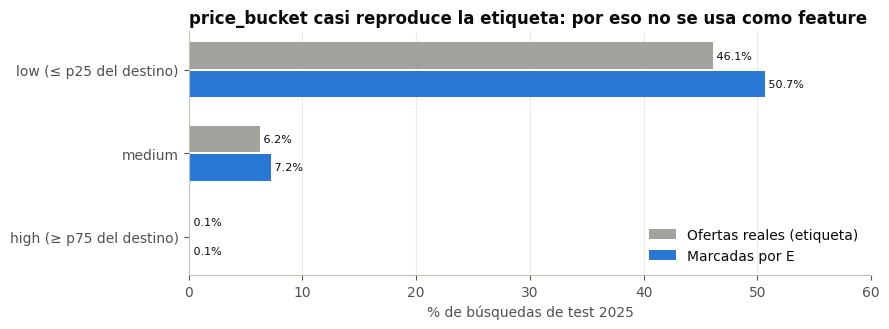

In [13]:
ver(figures.ofertas_por_price_bucket(T))

En `high` las ofertas son el 0,1%; en `low`, el 46%. El bucket se arma con el mismo precio que define la etiqueta, así que usarlo como feature sería darle la respuesta al modelo.

---
## 8. API

El algoritmo está servido con FastAPI (`api/main.py`) y empaquetado en Docker. La API usa la misma clase `DealDetector` que este notebook. Cada respuesta incluye una **explicación** de la decisión.

```bash
docker build -t hotel-deals-g2 . && docker run -p 8000:8000 hotel-deals-g2
# Documentación interactiva: http://localhost:8000/docs
```

Casos borde del test set compartido, evaluados por la API:

In [14]:
borde = pd.read_csv(OUT / "casos_borde_api.csv")
display(borde[["descripcion", "expected_decision", "api_decision", "ok"]].set_index("descripcion"))
ts = pd.read_csv(OUT / "metricas_test_set_compartido_api.csv").set_index("bloque")
display(tabla(ts[["n_evaluables", "precision", "recall", "f1", "fpr"]], pct_cols=["fpr"],
              dec_cols=["precision", "recall", "f1"]))

,expected_decision,api_decision,ok
descripcion,,,
"Destino top, precio 80% bajo la mediana",deal,deal,True
"Destino top, precio 3x la mediana",no_deal,no_deal,True
Ciudad inexistente en país conocido -> fallback país,deal|no_deal,no_deal,True
Ciudad nula -> fallback país,deal|no_deal,no_deal,True
País inexistente -> sin soporte,insufficient_data,insufficient_data,True
Ciudad sin mapeo con historia propia,deal|no_deal,no_deal,True
Precio absurdo (< 1 USD por persona-noche),invalid_price,invalid_price,True
Noches = 0,invalid_input,invalid_input,True
Noches = 45 (fuera de rango),invalid_input,invalid_input,True


,n_evaluables,precision,recall,f1,fpr
bloque,,,,,
real,3600,0.918,0.808,0.860,7.2%
sintetico,2400,0.813,0.813,0.813,7.4%


Los 11 casos borde dan la respuesta esperada: ciudades o países inexistentes, ciudad vacía, precio absurdo, noches fuera de rango y grupos grandes. El bloque real está balanceado 50/50 a propósito, así que su precision no se compara con la de la sección 4.

---
## 9. Conclusiones

### Qué se probó y qué se encontró

- Una **regla estadística** (z en logaritmo + descuento mínimo) con **cascada de fallback** detecta ofertas en el año siguiente con **F1 0,76** y decide en el 99% de las búsquedas.
- Rinde igual que un modelo de boosting y es explicable y simple de operar. Por eso es la elegida.
- El contexto del TP2 funciona: sacar el mes y la estadía empeora mucho. La semana del mes, en cambio, sobra con un solo año de historia.

### Supuestos

1. El precio se compara en USD por habitación-noche-persona.
2. Un mercado comparable es el mismo destino, mes, semana y estadía; si no hay datos, un nivel más amplio es un buen sustituto.
3. 30 búsquedas independientes alcanzan para estimar la mediana y la dispersión.
4. Dentro de cada contexto el precio es aproximadamente log-normal.
5. La historia reciente representa al mercado futuro, esta es la principal fuente de error y que se podria corregir con mas data de años anteriores o con modelos mas sofisticados que puedan intentar predecir el mercado hotelero.

### Qué no se pudo resolver

1. **Unidad de `avg_price_average` (riesgo principal).** La mediana casi no crece con las noches (138 USD con 1 noche, 208 con 7), así que parece ser una tarifa por noche. La fórmula heredada divide igual por las noches y hace que las estadías largas parezcan más baratas. Se mantuvo por consistencia con lo acordado.
2. **No hay categoría de hotel:** cada mercado mezcla hoteles económicos y de lujo.
3. **Deriva entre años:** El precio puede variar entre años por eventos unicos imposibles de predecir por el modelo.